# Clase 7 · Laboratorio — Modelos No Supervisados sobre Saber 11

**Trabajo en parejas · 90 min.**

En la pre-clase viste todos los modelos funcionando. En este laboratorio analizarás los datos desde ángulos más complejos: ¿cuántos perfiles de colegios existen en Colombia? ¿Qué departamentos son anomalías? ¿Se puede predecir el cluster de un nuevo estudiante?

**Checkpoint del profesor a los 50 min** (después de la Tarea 3).

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings('ignore')

df = pd.read_csv("datos/saber11_muestra_500k.csv")
df["ESTRATO_NUM"] = df["FAMI_ESTRATOVIVIENDA"].astype("string").str.extract(r"(\d+)").astype(float)
PUNTAJES = ["PUNT_LECTURA_CRITICA","PUNT_MATEMATICAS","PUNT_C_NATURALES",
            "PUNT_SOCIALES_CIUDADANAS","PUNT_INGLES"]

print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas")

Dataset: 500,000 filas × 52 columnas


## Tarea 1 (20 min) — Perfiles de colegios en Colombia

En lugar de segmentar estudiantes (como en la pre-clase), segmenta **colegios** usando su puntaje promedio.

1. Agrupa el dataset por `COLE_NOMBRE_ESTABLECIMIENTO` y calcula el promedio de los 5 puntajes y el estrato promedio. Filtra colegios con al menos 30 estudiantes.
2. Escala las variables.
3. Aplica K-Means y usa el método del codo + Silhouette para elegir K (entre 2 y 8).
4. Para cada cluster: ¿qué tipo de colegio describe? Muestra el promedio de las variables y la distribución de `COLE_NATURALEZA` y `COLE_AREA_UBICACION` dentro de cada cluster.
5. ¿Cuáles son los 5 colegios "más típicos" del cluster de mayor puntaje? ¿Los reconoces?

Colegios con ≥30 estudiantes: 5,034


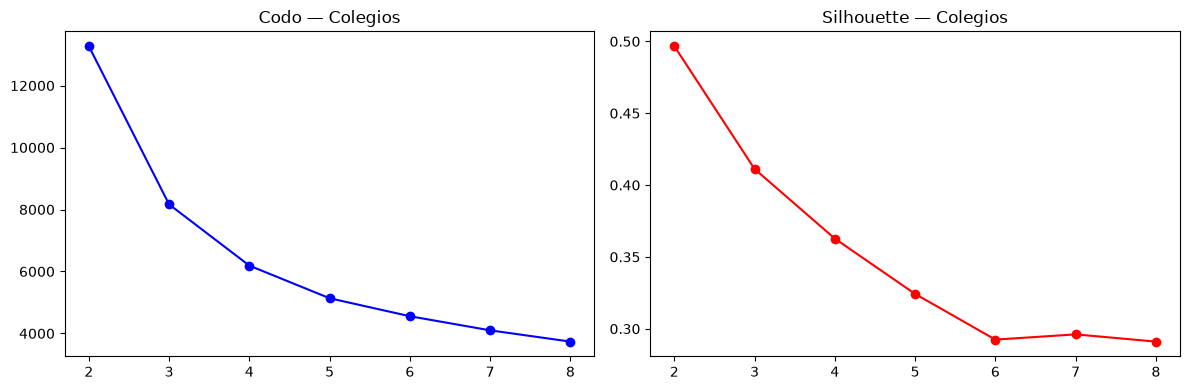

K sugerido: 2

=== Perfil por cluster ===
         PUNT_LECTURA_CRITICA  PUNT_MATEMATICAS  PUNT_C_NATURALES  \
cluster                                                             
0                        49.3              47.0              45.5   
1                        59.7              59.0              56.1   

         PUNT_SOCIALES_CIUDADANAS  PUNT_INGLES  ESTRATO_NUM  
cluster                                                      
0                            43.4         44.7          1.9  
1                            55.2         59.6          2.6  

=== Naturaleza por cluster ===
COLE_NATURALEZA  NO OFICIAL  OFICIAL
cluster                             
0                       471     3024
1                       789      750

=== Top 5 colegios del cluster élite (cluster 1) ===
COLE_NOMBRE_ESTABLECIMIENTO
COLEGIO ANGLO AMERICANO                                76.101266
COL NUEVO COLOMBO AMERICANO                            76.038298
COL BILINGUE DIVINO NIÑO                 

In [11]:
# 1: agregar por colegio (≥30 estudiantes)
colegios_extra = df.groupby("COLE_NOMBRE_ESTABLECIMIENTO").agg(
    n_estudiantes=("PUNT_MATEMATICAS","count"),
    COLE_NATURALEZA=("COLE_NATURALEZA","first"),
    COLE_AREA_UBICACION=("COLE_AREA_UBICACION","first"),
    COLE_JORNADA=("COLE_JORNADA","first") if "COLE_JORNADA" in df.columns else ("PUNT_MATEMATICAS","count"),
    **{p: (p,"mean") for p in PUNTAJES},
    ESTRATO_NUM=("ESTRATO_NUM","mean")
).query("n_estudiantes >= 30").dropna()

print(f"Colegios con ≥30 estudiantes: {len(colegios_extra):,}")
colegios = colegios_extra.copy()

# 2: escalar
X_colegios = StandardScaler().fit_transform(colegios[PUNTAJES + ["ESTRATO_NUM"]])

# 3: Elbow + Silhouette
inercias_c, silhouettes_c = [], []
for k in range(2, 9):
    km_c = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels_c = km_c.fit_predict(X_colegios)
    inercias_c.append(km_c.inertia_)
    silhouettes_c.append(silhouette_score(X_colegios, labels_c))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias_c, "b-o"); axes[0].set_title("Codo — Colegios")
axes[1].plot(range(2, 9), silhouettes_c, "r-o"); axes[1].set_title("Silhouette — Colegios")
plt.tight_layout(); plt.show()

# 4: K-Means final + perfil
K_col = range(2, 9)[np.argmax(silhouettes_c)]  # tu K elegido
print(f"K sugerido: {K_col}")
km_col = KMeans(n_clusters=K_col, n_init=10, random_state=42)
colegios["cluster"] = km_col.fit_predict(X_colegios)

print("\n=== Perfil por cluster ===")
print(colegios.groupby("cluster")[PUNTAJES + ["ESTRATO_NUM"]].mean().round(1))
print("\n=== Naturaleza por cluster ===")
print(colegios.groupby(["cluster","COLE_NATURALEZA"]).size().unstack(fill_value=0))

# 5: top 5 colegios del cluster élite
cluster_elite = colegios.groupby("cluster")[PUNTAJES].mean().sum(axis=1).idxmax()
top5 = colegios[colegios["cluster"]==cluster_elite][PUNTAJES].mean(axis=1).nlargest(5)
print(f"\n=== Top 5 colegios del cluster élite (cluster {cluster_elite}) ===")
print(top5)
print(colegios.groupby(["cluster", "COLE_AREA_UBICACION"])
      .size().unstack(fill_value=0))

In [ ]:
# Visualización PCA de clusters de colegios
pca_col = PCA(n_components=2)
coords_col = pca_col.fit_transform(X_colegios)
colores_col = plt.cm.Set1(np.linspace(0,1,K_col))

fig, ax = plt.subplots(figsize=(9,6))
for k in range(K_col):
    mask = colegios["cluster"] == k
    ax.scatter(coords_col[mask,0], coords_col[mask,1], alpha=0.5, s=10,
               color=colores_col[k], label=f"Cluster {k} (n={mask.sum()})")
ax.set_xlabel(f"PC1 ({pca_col.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca_col.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("Colegios por cluster — Proyección PCA 2D")
ax.legend(); plt.tight_layout(); plt.show()

**Pregunta analítica:** ¿Los clusters de colegios coinciden con lo que esperarías según la naturaleza del colegio (oficial vs privado) o su ubicación (urbano vs rural)?

## Tarea 2 (15 min) — Anomalías en el perfil de colegios

Usa DBSCAN sobre el mismo dataset de colegios para detectar colegios con perfiles inusuales.

1. Aplica DBSCAN con `eps=1.0, min_samples=3`.
2. ¿Cuántos colegios son "ruido" (-1)?
3. Muestra el perfil de los colegios anómalos: ¿tienen puntajes extremadamente altos, extremadamente bajos, o una combinación inusual?
4. ¿Qué tienen en común los colegios etiquetados como ruido? (Revisa `COLE_NATURALEZA`, `COLE_AREA_UBICACION`, `COLE_JORNADA`).

In [ ]:
# 1: DBSCAN sobre X_colegios
db = DBSCAN(eps=1.0, min_samples=3)
colegios["cluster_db"] = db.fit_predict(X_colegios)

# 2: conteo de ruido
n_anomalos = (colegios["cluster_db"] == -1).sum()
print(f"Colegios anómalos (ruido): {n_anomalos} de {len(colegios)} ({n_anomalos/len(colegios)*100:.1f}%)")

# 3: perfil de anomalías
anomalos = colegios[colegios["cluster_db"] == -1]
normales = colegios[colegios["cluster_db"] != -1]
print("\nPerfil anómalos vs normales:")
comp = pd.concat([
    anomalos[PUNTAJES].mean().rename("Anómalos"),
    normales[PUNTAJES].mean().rename("Normales")
], axis=1).round(1)
print(comp)

# 4: características comunes de anómalos
print("\nNaturaleza de anómalos:")
print(anomalos["COLE_NATURALEZA"].value_counts())
print("\nÁrea de anómalos:")
print(anomalos["COLE_AREA_UBICACION"].value_counts())

Colegios anómalos (ruido): 9 de 5034 (0.2%)

Perfil anómalos vs normales:
                          Anómalos  Normales
PUNT_LECTURA_CRITICA          43.2      52.5
PUNT_MATEMATICAS              39.8      50.7
PUNT_C_NATURALES              39.2      48.8
PUNT_SOCIALES_CIUDADANAS      37.8      47.0
PUNT_INGLES                   40.1      49.3

Naturaleza de anómalos:
COLE_NATURALEZA
OFICIAL       8
NO OFICIAL    1
Name: count, dtype: int64

Área de anómalos:
COLE_AREA_UBICACION
RURAL     6
URBANO    3
Name: count, dtype: int64


In [ ]:
# Visualizar anómalos en espacio PCA
fig, ax = plt.subplots(figsize=(9,6))
mask_normal = colegios["cluster_db"] != -1
mask_anomalo = colegios["cluster_db"] == -1
ax.scatter(coords_col[mask_normal,0], coords_col[mask_normal,1],
           alpha=0.4, s=8, c="steelblue", label="Normal")
ax.scatter(coords_col[mask_anomalo,0], coords_col[mask_anomalo,1],
           alpha=0.9, s=40, c="red", marker="x", linewidths=1.5, label=f"Anómalo (n={mask_anomalo.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("DBSCAN — Colegios anómalos destacados en espacio PCA")
ax.legend(); plt.tight_layout(); plt.show()

## Tarea 3 (15 min) — ¿Suave o duro?

Usando el mismo K que encontraste en la Tarea 1:

1. Aplica GMM con el mismo K sobre los colegios.
2. Compara las métricas (Silhouette, Davies-Bouldin) de K-Means vs GMM.
3. Identifica los colegios con **alta incertidumbre** (probabilidad máxima < 0.70). ¿Qué tipo de colegio tiende a quedar "entre dos clusters"?
4. ¿En qué caso preferirías el output probabilístico de GMM sobre el duro de K-Means para tomar decisiones de política educativa?

In [ ]:
# TODO 1: GMM
gmm_col = GaussianMixture(n_components=K_col, random_state=42)
gmm_col.fit(X_colegios)
colegios["cluster_gmm"] = gmm_col.predict(X_colegios)

# TODO 2: métricas
sil_km_c  = silhouette_score(X_colegios, colegios["cluster"])
sil_gmm_c = silhouette_score(X_colegios, colegios["cluster_gmm"])
db_km_c   = davies_bouldin_score(X_colegios, colegios["cluster"])
db_gmm_c  = davies_bouldin_score(X_colegios, colegios["cluster_gmm"])
print(f"K-Means  → Silhouette: {sil_km_c:.4f}  |  Davies-Bouldin: {db_km_c:.4f}")
print(f"GMM      → Silhouette: {sil_gmm_c:.4f}  |  Davies-Bouldin: {db_gmm_c:.4f}")

# TODO 3: colegios inciertos
proba = gmm_col.predict_proba(X_colegios)
colegios["max_proba"] = proba.max(axis=1)
inciertos = colegios[colegios["max_proba"] < 0.70]
print(f"\nColegios inciertos (prob < 70%): {len(inciertos)} ({len(inciertos)/len(colegios)*100:.1f}%)")
print(inciertos[["COLE_NATURALEZA","COLE_AREA_UBICACION","max_proba"] + PUNTAJES].head(10))

**¿Cuándo preferirías GMM sobre K-Means para política educativa?**

_(Escribe tu respuesta aquí: piensa en casos donde la incertidumbre sea valiosa para la toma de decisiones, por ejemplo focalización de recursos, intervenciones diferenciadas, etc.)_

## Checkpoint del profesor (10 min)

Discutimos:
- ¿Qué K elegiste y por qué (Elbow o Silhouette)?
- ¿Los colegios anómalos de DBSCAN son "malos" o simplemente "distintos"?
- ¿Tiene sentido usar PCA antes de aplicar clustering? ¿Cuándo sí y cuándo no?

## Tarea 4 (20 min) — ¿Colombia mejoró entre 2019 y 2022?

1. Calcula el puntaje promedio por departamento para el período **20194** y para **20224** por separado.
2. Aplica clustering jerárquico (Ward) sobre los promedios de 2019 y compara con los de 2022.
3. Grafica ambos dendrogramas lado a lado.
4. ¿Qué departamentos cambiaron de "grupo" entre 2019 y 2022?
5. ¿Es posible afirmar que Colombia "mejoró" globalmente? ¿Qué métricas usarías para responder esa pregunta?

In [ ]:
# TODO 1: promedios por departamento y período
col_periodo = "PERIODO" if "PERIODO" in df.columns else df.columns[df.columns.str.contains("PERIOD",case=False)][0] if df.columns.str.contains("PERIOD",case=False).any() else None
if col_periodo:
    prof_2019 = (df[df[col_periodo]==20194]
                 .groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna())
    prof_2022 = (df[df[col_periodo]==20224]
                 .groupby("COLE_DEPTO_UBICACION")[PUNTAJES].mean().dropna())
    # Departamentos comunes
    deptos_comunes = prof_2019.index.intersection(prof_2022.index)
    prof_2019 = prof_2019.loc[deptos_comunes]
    prof_2022 = prof_2022.loc[deptos_comunes]
    print(f"Departamentos comunes 2019-2022: {len(deptos_comunes)}")
else:
    print("Columna de período no encontrada. Verifica los nombres de columnas:")
    print([c for c in df.columns if "period" in c.lower() or "año" in c.lower() or "year" in c.lower()])

# TODO 2-3: clustering jerárquico + dendrogramas
sc = StandardScaler()
X_2019 = sc.fit_transform(prof_2019)
X_2022 = sc.fit_transform(prof_2022)

linked_2019 = linkage(X_2019, method='ward')
linked_2022 = linkage(X_2022, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, linked, etiquetas, titulo in [
    (axes[0], linked_2019, prof_2019.index.tolist(), "Dendrograma 2019"),
    (axes[1], linked_2022, prof_2022.index.tolist(), "Dendrograma 2022")
]:
    dendrogram(linked, labels=etiquetas, ax=ax, leaf_rotation=45, leaf_font_size=8)
    ax.set_title(titulo)
    ax.set_ylabel("Distancia Ward")
plt.suptitle("Evolución de agrupaciones departamentales: 2019 vs 2022", fontsize=13)
plt.tight_layout(); plt.show()

# TODO 4: departamentos que cambiaron de cluster
agg_2019 = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_2022 = AgglomerativeClustering(n_clusters=3, linkage='ward')
etiq_2019 = agg_2019.fit_predict(X_2019)
etiq_2022 = agg_2022.fit_predict(X_2022)

cambios = pd.DataFrame({"Depto": deptos_comunes, "Cluster_2019": etiq_2019, "Cluster_2022": etiq_2022})
cambios_reales = cambios[cambios["Cluster_2019"] != cambios["Cluster_2022"]]
print(f"\nDepartamentos que cambiaron de cluster: {len(cambios_reales)}")
print(cambios_reales.to_string(index=False))

# TODO 5: análisis comparativo
print("\n=== Promedio nacional por período ===")
print(f"2019: {prof_2019.mean().mean():.2f}")
print(f"2022: {prof_2022.mean().mean():.2f}")

## Tarea 5 (10 min) — Clustering en el P2/3

1. Sobre el dataset del proyecto de tu grupo, aplica K-Means (o DBSCAN si tiene sentido) como el **modelo no supervisado requerido** en la Fase C.
2. Calcula el Silhouette Score.
3. Describe en 3-4 frases qué significan los clusters encontrados en términos del negocio/dominio de tu dataset.

In [ ]:
# TODO: cargar dataset del proyecto
# df_proyecto = pd.read_csv("ruta/al/dataset.csv")

# TODO: seleccionar features numéricas relevantes
# features = [...]
# X_proy = StandardScaler().fit_transform(df_proyecto[features].dropna())

# TODO: clustering + silhouette
# km_proy = KMeans(n_clusters=..., n_init=10, random_state=42)
# labels_proy = km_proy.fit_predict(X_proy)
# sil_proy = silhouette_score(X_proy, labels_proy)
# print(f"Silhouette Score del proyecto: {sil_proy:.4f}")

print("Completa los TODOs con el dataset de tu proyecto")

**Interpretación de negocio de los clusters:**

_(Escribe aquí en 3-4 frases: ¿qué tipo de observaciones agrupa cada cluster? ¿Qué nombre le darías a cada grupo en términos del dominio de tu proyecto?)_

## Entrega

**Nombre del archivo:** `02_laboratorio_apellido1_apellido2.ipynb`

**Sube a:** Moodle → Clase 7 → Laboratorio.

**Criterios de evaluación:**
- Tareas 1-4: código funcional + análisis escrito de los resultados
- Tarea 5: aplicado al dataset del proyecto con interpretación de negocio
- Reflexiones escritas en celdas markdown